In [1]:
from config_structured_documents_graph import Settings
from dotenv import load_dotenv

load_dotenv()
settings = Settings()

In [2]:
import base64
import fitz
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langgraph.graph import END, START, StateGraph, MessagesState
from PIL import Image as PILImage
import io
import pytesseract
import json
from pydantic import BaseModel, Field
from typing import Any
from sentence_transformers import SentenceTransformer
import numpy as np
from pathlib import Path


pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
_model = SentenceTransformer('all-MiniLM-L6-v2')  # ~80 МБ, скачивается один раз


vlm = ChatOpenAI(
    model="cyankiwi/Qwen3-VL-8B-Instruct-AWQ-4bit",
    base_url="https://skillet-appealing-broken.ngrok-free.dev/v1",
    api_key="not-needed",
    max_tokens=4900,
)

class MessagesState(MessagesState):
    pages_data : list[dict]
    data_after_check: list[dict]
    rule_groups: list[dict]

class RuleGroup(BaseModel):
    attribute: str = Field(description="Name of the attribute this group of rules belongs to, determined from the meaning of the text")
    rules: list[str] = Field(description="List of rules/requirements relating to this attribute")

class GroupingResult(BaseModel):
    groups: list[RuleGroup] = Field(description="List of all found rule groups by attribute")

def first_node(state: MessagesState) -> MessagesState:
    _document = fitz.open("API-600.pdf")

    received_text = []
    pages_data = []  # <-- сюда будем собирать данные для JSON

    for page_number in range(len(_document)):

        first_page = _document[page_number]

        pix = first_page.get_pixmap(dpi=160)

        img = PILImage.open(io.BytesIO(pix.tobytes("png")))

        detected_angle = 0
        confidence = 0.0
        try:
            osd = pytesseract.image_to_osd(img)
            detected_angle = int(
                [line for line in osd.split("\n") if "Rotate" in line][0].split(":")[1].strip()
            )
            confidence = float(
                [line for line in osd.split("\n") if "Orientation confidence" in line][0].split(":")[1].strip()
            )
            print(f"OSD detected rotation: {detected_angle}°, confidence: {confidence}")
        except pytesseract.TesseractError as e:
            print(f"OSD не смог определить ориентацию: {e}")

        if detected_angle != 0 and confidence >= 1.0:
            img_rotated = img.rotate(-detected_angle, expand=True)
            print(f"Изображение повёрнуто на {-detected_angle}°")
        else:
            img_rotated = img
            print("Поворот не применялся (угол 0 или низкая уверенность)")

        # img_rotated.save(f"rotated_page_{page_number}_1.png")

        buf = io.BytesIO()
        img_rotated.save(buf, format="PNG")

        image_bytes = pix.tobytes()
        image_base64 = base64.b64encode(buf.getvalue()).decode("utf-8")

        message = HumanMessage(content=[
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}},
            {"type": "text", "text": "Extract text from this page."}
        ])

        response = vlm.invoke([SystemMessage(content=settings.VL_prompt), message])
        token_usage = response.response_metadata.get("token_usage")
        print(token_usage)

        received_text.append(response)

        # собираем запись для JSON
        pages_data.append({
            "page_number": page_number,
            "source_page_index": page_number,
            "detected_angle": detected_angle,
            "confidence": confidence,
            "content": response.content,
            "token_usage": token_usage,
        })

    # запись в JSON вместо markdown
    # with open("output.json", "w", encoding="utf-8") as f:
    #     json.dump(pages_data, f, ensure_ascii=False, indent=2)

    return {"messages": received_text, "pages_data": pages_data}

def formatting_text_node(state: MessagesState) -> MessagesState:
    llm = ChatOpenAI(model=settings.llmodel, temperature=0, model_kwargs={"response_format": {"type": "json_object"}})

    pages_after_llm = []
    pages = state.get("pages_data")

    if len(pages) == 1:
        # отдельная обработка единственной страницы без пары
        page_copy = dict(pages[0])
        try:
            page_copy["content"] = json.loads(pages[0]["content"])
        except json.JSONDecodeError:
            print("error pass")

        result = llm.invoke([
            SystemMessage(content=settings.llm_prompt),
            HumanMessage(content=json.dumps([page_copy], ensure_ascii=False)),
        ])
        parsed = json.loads(result.content)
        print(f"\n\nsource: {parsed}\n\n")
        result_page = parsed["pages"][0]
        pages_after_llm.append(result_page)
        print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

    else:
        for i in range(0, len(pages) - 1):
            page_copy = [dict(pages[i]), dict(pages[i + 1])]
            for index, original in enumerate((pages[i], pages[i + 1])):
                try:
                    page_copy[index]["content"] = json.loads(original["content"])
                except json.JSONDecodeError:
                    print("error pass")

            result = llm.invoke([
                SystemMessage(content=settings.llm_prompt),
                HumanMessage(content=json.dumps(page_copy, ensure_ascii=False)),
            ])
            # ожидаем, что модель вернёт только одну страницу (первую из пары)
            parsed = json.loads(result.content)
            print(f"\n\nsource: {parsed}\n\n")
            result_page = parsed["pages"][0]
            pages_after_llm.append(result_page)
            print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

        # последняя страница никогда не была "первой" в паре — обработать отдельно
        last_page = dict(pages[-1])
        try:
            last_page["content"] = json.loads(pages[-1]["content"])
        except json.JSONDecodeError:
            print("error pass")

        result = llm.invoke([
            SystemMessage(content=settings.llm_prompt),
            HumanMessage(content=json.dumps([last_page], ensure_ascii=False)),
        ])
        parsed = json.loads(result.content)
        print(f"\n\nsource: {parsed}\n\n")
        result_page = parsed["pages"][0]
        pages_after_llm.append(result_page)
        print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

    # print(f"\n\ndata_after_check {pages_after_llm}\n\n")

    return {
        "messages": [AIMessage(content=json.dumps(pages_after_llm, ensure_ascii=False))],
        "data_after_check": pages_after_llm,
    }







# --- локальная VL-модель, используется здесь БЕЗ картинки — только текст ---
grouping_llm = ChatOpenAI(
    model=settings.VL_model,
    base_url=settings.VL_url,
    api_key=settings.VL_api_key,
    max_tokens=10000,  # с запасом: таблицы/длинные страницы могут дать длинный ответ
    temperature=0,
)

# добавляем к промпту явное требование формата — раз мы больше не полагаемся
# на with_structured_output (guided decoding), модель должна получить точную
# инструкцию по схеме прямо текстом

# JSON_SCHEMA_INSTRUCTION = """
#
# === ФОРМАТ ОТВЕТА (СТРОГО ОБЯЗАТЕЛЬНО) ===
#
# Верни ТОЛЬКО валидный JSON, без markdown-разметки (без ```json), без пояснений
# до или после — ничего, кроме самого JSON. Строго такая структура:
#
# {
#   "groups": [
#     {
#       "attribute": "название атрибута",
#       "rules": ["правило 1", "правило 2"]
#     }
#   ]
# }
#
# Если ни одного правила не найдено — верни {"groups": []}."""


def load_existing_rule_groups(path: Path = settings.RULES_STORAGE_PATH) -> list[dict]:
    """Загружает ранее сохранённые группы правил, если файл существует.
    Если файла нет или он битый — возвращает пустой список (начинаем с нуля)."""
    if not path.exists():
        return []
    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        if not isinstance(data, list):
            print(f"WARNING: {path} содержит не список, игнорируем файл")
            return []
        return data
    except json.JSONDecodeError as e:
        print(f"WARNING: не удалось распарсить {path}: {e}. Начинаем с пустого списка")
        return []

def load_existing_rule_groups(path: Path = settings.RULES_STORAGE_PATH) -> list[dict]:
    """Загружает ранее сохранённые группы правил, если файл существует.
    Если файла нет или он битый — возвращает пустой список (начинаем с нуля)."""
    if not path.exists():
        return []
    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        if not isinstance(data, list):
            print(f"WARNING: {path} содержит не список, игнорируем файл")
            return []
        return data
    except json.JSONDecodeError as e:
        print(f"WARNING: не удалось распарсить {path}: {e}. Начинаем с пустого списка")
        return []


def save_rule_groups(groups: list[dict], path: Path = settings.RULES_STORAGE_PATH) -> None:
    """Сохраняет итоговые группы правил в файл, перезаписывая предыдущую версию."""
    with open(path, "w", encoding="utf-8") as f:
        json.dump(groups, f, ensure_ascii=False, indent=2)
    print(f"Сохранено {len(groups)} групп правил в {path}")


def grouping_rules_node(state: MessagesState) -> MessagesState:
    source_data = state.get("data_after_check") or state.get("pages_data")

    # --- загружаем уже накопленные ранее правила (если есть) ---
    existing_groups = load_existing_rule_groups()
    all_groups: list[dict] = list(existing_groups)  # стартуем с того, что уже было

    # известные атрибуты — сразу подтягиваем из уже сохранённых данных,
    # чтобы модель не придумывала новые названия для уже встречавшихся атрибутов
    known_attributes: list[str] = [g["attribute"] for g in existing_groups]

    if existing_groups:
        print(f"Загружено {len(existing_groups)} ранее сохранённых групп правил")

    def prepare(page):
        page_copy = dict(page)
        content = page.get("content")
        if isinstance(content, str):
            try:
                page_copy["content"] = json.loads(content)
            except json.JSONDecodeError:
                pass
        return page_copy

    def call_llm(pages_chunk):
        nonlocal all_groups, known_attributes

        hint = ""
        if known_attributes:
            hint = (
                # "\n\nThe following attributes have already been identified: "
                # + ", ".join(known_attributes)
                # + ". If the new rule relates to one of them, use EXACTLY "
                #   "the same attribute name — do not invent a new wording."
                ""
            )

        full_prompt = settings.TABLE_EXTRACTION_PROMPT + hint  # + JSON_SCHEMA_INSTRUCTION

        message = HumanMessage(content=[
            {"type": "text", "text": json.dumps(pages_chunk, ensure_ascii=False)}
        ])

        print(f"to the grouping rules model:\n{json.dumps(pages_chunk, ensure_ascii=False)}\n")

        response = grouping_llm.invoke([SystemMessage(content=full_prompt), message])
        print(f"\ngrouping tokens: {response.response_metadata.get('token_usage')}")

        print(f"\nresponse llm:\n{response.content}\n")
        try:
            parsed = json.loads(response.content)
            result = GroupingResult.model_validate(parsed)
        except (json.JSONDecodeError, Exception) as e:
            print("PARSING ERROR:", e)
            print("RAW OUTPUT:", response.content)
            raise

        for g in result.groups:
            g_dict = g.model_dump()
            all_groups.append(g_dict)
            if g_dict["attribute"] not in known_attributes:
                known_attributes.append(g_dict["attribute"])

    if len(source_data) == 1:
        call_llm([prepare(source_data[0])])
    else:
        for i in range(len(source_data)):
            call_llm([prepare(source_data[i])])

    # --- сохраняем накопленный результат обратно в файл, без дедупликации ---
    save_rule_groups(all_groups)

    return {"rule_groups": all_groups}

builder = StateGraph(MessagesState)
builder.add_node(first_node)
builder.add_node(formatting_text_node)
builder.add_node(grouping_rules_node)
builder.add_edge(START, "first_node")
builder.add_edge("first_node", "formatting_text_node")
builder.add_edge("formatting_text_node", "grouping_rules_node")
builder.add_edge("grouping_rules_node", END)
graph = builder.compile()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

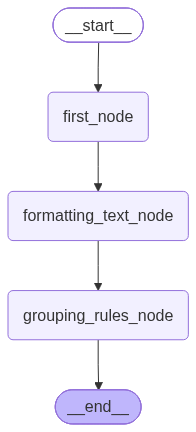

In [3]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [6]:
inv = graph.invoke({"messages": []})

# for message in inv["messages"]:
#     message.pretty_print()

print(inv.get("rule_groups"))

OSD detected rotation: 0°, confidence: 0.97
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 211, 'prompt_tokens': 4302, 'total_tokens': 4513, 'completion_tokens_details': None, 'prompt_tokens_details': None}
OSD detected rotation: 0°, confidence: 12.6
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 626, 'prompt_tokens': 4302, 'total_tokens': 4928, 'completion_tokens_details': None, 'prompt_tokens_details': None}
OSD detected rotation: 0°, confidence: 13.05
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 498, 'prompt_tokens': 4302, 'total_tokens': 4800, 'completion_tokens_details': None, 'prompt_tokens_details': None}
OSD не смог определить ориентацию: (1, 'Estimating resolution as 110 Warning. Invalid resolution 0 dpi. Using 70 instead. Too few characters. Skipping this page Error during processing.')
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 41, 'prompt_tokens': 4302, 

In [5]:
"""
Тестовый скрипт: проверяем, справляется ли cyankiwi/Qwen3-VL-8B-Instruct-AWQ-4bit
с ПОЛНЫМ построчным извлечением правил из большой таблицы, если отправить
ей чистый текст (без изображения).

Используем ровно ту таблицу (Table 1, 26 строк x 6 колонок классов), на которой
gpt-4o уже показал неполное извлечение (5 правил из ~150 возможных значений) —
чтобы сравнение было честным, на одинаковых данных.
"""

import json
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage

VL_model = "cyankiwi/Qwen3-VL-8B-Instruct-AWQ-4bit"
VL_url = "https://skillet-appealing-broken.ngrok-free.dev/v1"
VL_api_key = "not-needed"

vlm_text = ChatOpenAI(
    model=VL_model,
    base_url=VL_url,
    api_key=VL_api_key,
    max_tokens=8000,  # намеренно с запасом — таблица большая, ответ будет длинным
    temperature=0,
)

llm_model = ChatOpenAI(model = settings.llmodel, temperature=0)

# ровно та таблица, что была на странице 10 в вашем прогоне
table_block = {
    "type": "table",
    "title": "Table 1—Minimum Wall Thickness for Body and Bonnet",
    "columns": ["Class Designation", "150", "300", "600", "900", "1500", "2500"],
    "rows": [
        {"Class Designation": "1", "150": "6.4 (0.25)", "300": "6.4 (0.25)", "600": "7.9 (0.31)", "900": "12.7 (0.50)", "1500": "12.7 (0.50)", "2500": "15.0 (0.59)"},
        {"Class Designation": "1¼", "150": "6.4 (0.25)", "300": "6.4 (0.25)", "600": "8.6 (0.34)", "900": "14.2 (0.56)", "1500": "14.2 (0.56)", "2500": "17.5 (0.69)"},
        {"Class Designation": "1 ½", "150": "6.4 (0.25)", "300": "7.9 (0.31)", "600": "9.4 (0.37)", "900": "15.0 (0.59)", "1500": "15.0 (0.59)", "2500": "19.1 (0.75)"},
        {"Class Designation": "2", "150": "8.6 (0.34)", "300": "9.7 (0.38)", "600": "11.2 (0.44)", "900": "19.1 (0.75)", "1500": "19.1 (0.75)", "2500": "22.4 (0.88)"},
        {"Class Designation": "2½", "150": "9.7 (0.38)", "300": "11.2 (0.44)", "600": "11.9 (0.47)", "900": "22.4 (0.88)", "1500": "22.4 (0.88)", "2500": "25.4 (1.00)"},
        {"Class Designation": "3", "150": "10.4 (0.41)", "300": "11.9 (0.47)", "600": "12.7 (0.50)", "900": "19.1 (0.75)", "1500": "23.9 (0.94)", "2500": "30.2 (1.19)"},
        {"Class Designation": "4", "150": "11.2 (0.44)", "300": "12.7 (0.50)", "600": "16.0 (0.63)", "900": "21.3 (0.84)", "1500": "28.7 (1.13)", "2500": "35.8 (1.41)"},
        {"Class Designation": "6", "150": "11.9 (0.47)", "300": "16.0 (0.63)", "600": "19.1 (0.75)", "900": "26.2 (1.03)", "1500": "38.1 (1.50)", "2500": "48.5 (1.91)"},
        {"Class Designation": "8", "150": "12.7 (0.50)", "300": "17.5 (0.69)", "600": "25.4 (1.00)", "900": "31.8 (1.25)", "1500": "47.8 (1.88)", "2500": "62.0 (2.44)"},
        {"Class Designation": "10", "150": "14.2 (0.56)", "300": "19.1 (0.75)", "600": "28.7 (1.13)", "900": "36.6 (1.44)", "1500": "57.2 (2.25)", "2500": "67.6 (2.66)"},
        {"Class Designation": "12", "150": "16.0 (0.63)", "300": "20.6 (0.81)", "600": "31.8 (1.25)", "900": "42.2 (1.66)", "1500": "66.8 (2.63)", "2500": "86.6 (3.41)"},
        {"Class Designation": "14", "150": "16.8 (0.66)", "300": "22.4 (0.88)", "600": "35.1 (1.38)", "900": "46.0 (1.81)", "1500": "69.9 (2.75)", "2500": "—"},
        {"Class Designation": "16", "150": "17.5 (0.69)", "300": "23.9 (0.94)", "600": "38.1 (1.50)", "900": "52.3 (2.06)", "1500": "79.5 (3.13)", "2500": "—"},
        {"Class Designation": "18", "150": "18.3 (0.72)", "300": "25.4 (1.00)", "600": "41.4 (1.63)", "900": "57.2 (2.25)", "1500": "88.9 (3.50)", "2500": "—"},
        {"Class Designation": "20", "150": "19.1 (0.75)", "300": "26.9 (1.06)", "600": "44.5 (1.75)", "900": "63.5 (2.50)", "1500": "98.6 (3.88)", "2500": "—"},
        {"Class Designation": "24", "150": "20.6 (0.81)", "300": "30.2 (1.19)", "600": "50.8 (2.00)", "900": "73.2 (2.88)", "1500": "114.3 (4.50)", "2500": "—"},
        {"Class Designation": "26", "150": "21.4 (0.84)", "300": "31.6 (1.24)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "28", "150": "22.2 (0.87)", "300": "33.3 (1.31)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "30", "150": "23.0 (0.91)", "300": "34.9 (1.37)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "32", "150": "23.8 (0.94)", "300": "36.0 (1.41)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "34", "150": "24.6 (0.97)", "300": "38.1 (1.50)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "36", "150": "25.3 (1.00)", "300": "39.6 (1.56)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "38", "150": "26.1 (1.03)", "300": "41.3 (1.63)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "40", "150": "27.0 (1.06)", "300": "43.0 (1.69)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
        {"Class Designation": "42", "150": "27.7 (1.09)", "300": "44.4 (1.75)", "600": "—", "900": "—", "1500": "—", "2500": "—"},
    ],
}

# считаем ожидаемое число непустых ячеек-значений (это "истина", с которой сверяем)
expected_values = 0
for row in table_block["rows"]:
    for col in table_block["columns"][1:]:  # первая колонка — идентификатор, не значение
        if row.get(col) not in ("", "—", "NA", None):
            expected_values += 1

print(f"Ожидаемое количество значений (непустых ячеек) в таблице: {expected_values}")

TABLE_EXTRACTION_PROMPT = """Ты извлекаешь технические правила из ОДНОЙ таблицы нормативного документа.

Тебе дана таблица в формате JSON: title, columns, rows.

Твоя задача — пройтись по КАЖДОЙ строке и КАЖДОМУ значению (кроме пустых/прочерков) и
сформулировать для каждого отдельное правило вида:
"Для класса {класс} и номинального размера {DN} минимальная толщина стенки составляет {значение}."

ОБЯЗАТЕЛЬНО обработай ВСЕ строки таблицы от первой до последней, без исключений и без
сокращения количества — не давай "несколько примеров", а обработай таблицу ПОЛНОСТЬЮ.
Пропускай только значения "—", "NA" или пустые.

Верни ТОЛЬКО валидный JSON списком строк-правил, без markdown, без пояснений:
["правило 1", "правило 2", ...]
"""

message = HumanMessage(content=[
    {"type": "text", "text": json.dumps(table_block, ensure_ascii=False)}
])

response = vlm_text.invoke([SystemMessage(content=settings.TABLE_EXTRACTION_PROMPT), message])

print("\n--- RAW OUTPUT ---")
print(response.content)

try:
    rules = json.loads(response.content)
    print(f"\nМодель вернула {len(rules)} правил из {expected_values} ожидаемых значений.")
    print(f"Полнота: {len(rules) / expected_values * 100:.1f}%")
except json.JSONDecodeError as e:
    print(f"\nНе удалось распарсить JSON: {e}")

print("\nToken usage:", response.response_metadata.get("token_usage"))

Ожидаемое количество значений (непустых ячеек) в таблице: 109

--- RAW OUTPUT ---
{
  "groups": [
    {
      "attribute": "Minimum Wall Thickness for Body and Bonnet",
      "rules": [
        "For Class Designation 1, minimum wall thickness is 6.4 (0.25) for 150, 300, and 600; 7.9 (0.31) for 600; 12.7 (0.50) for 900, 1500; and 15.0 (0.59) for 2500.",
        "For Class Designation 1¼, minimum wall thickness is 6.4 (0.25) for 150, 300; 8.6 (0.34) for 600; 14.2 (0.56) for 900, 1500; and 17.5 (0.69) for 2500.",
        "For Class Designation 1½, minimum wall thickness is 6.4 (0.25) for 150; 7.9 (0.31) for 300; 9.4 (0.37) for 600; 15.0 (0.59) for 900, 1500; and 19.1 (0.75) for 2500.",
        "For Class Designation 2, minimum wall thickness is 8.6 (0.34) for 150; 9.7 (0.38) for 300; 11.2 (0.44) for 600; 19.1 (0.75) for 900, 1500; and 22.4 (0.88) for 2500.",
        "For Class Designation 2½, minimum wall thickness is 9.7 (0.38) for 150; 11.2 (0.44) for 300; 11.9 (0.47) for 600; 22.4 (0.8